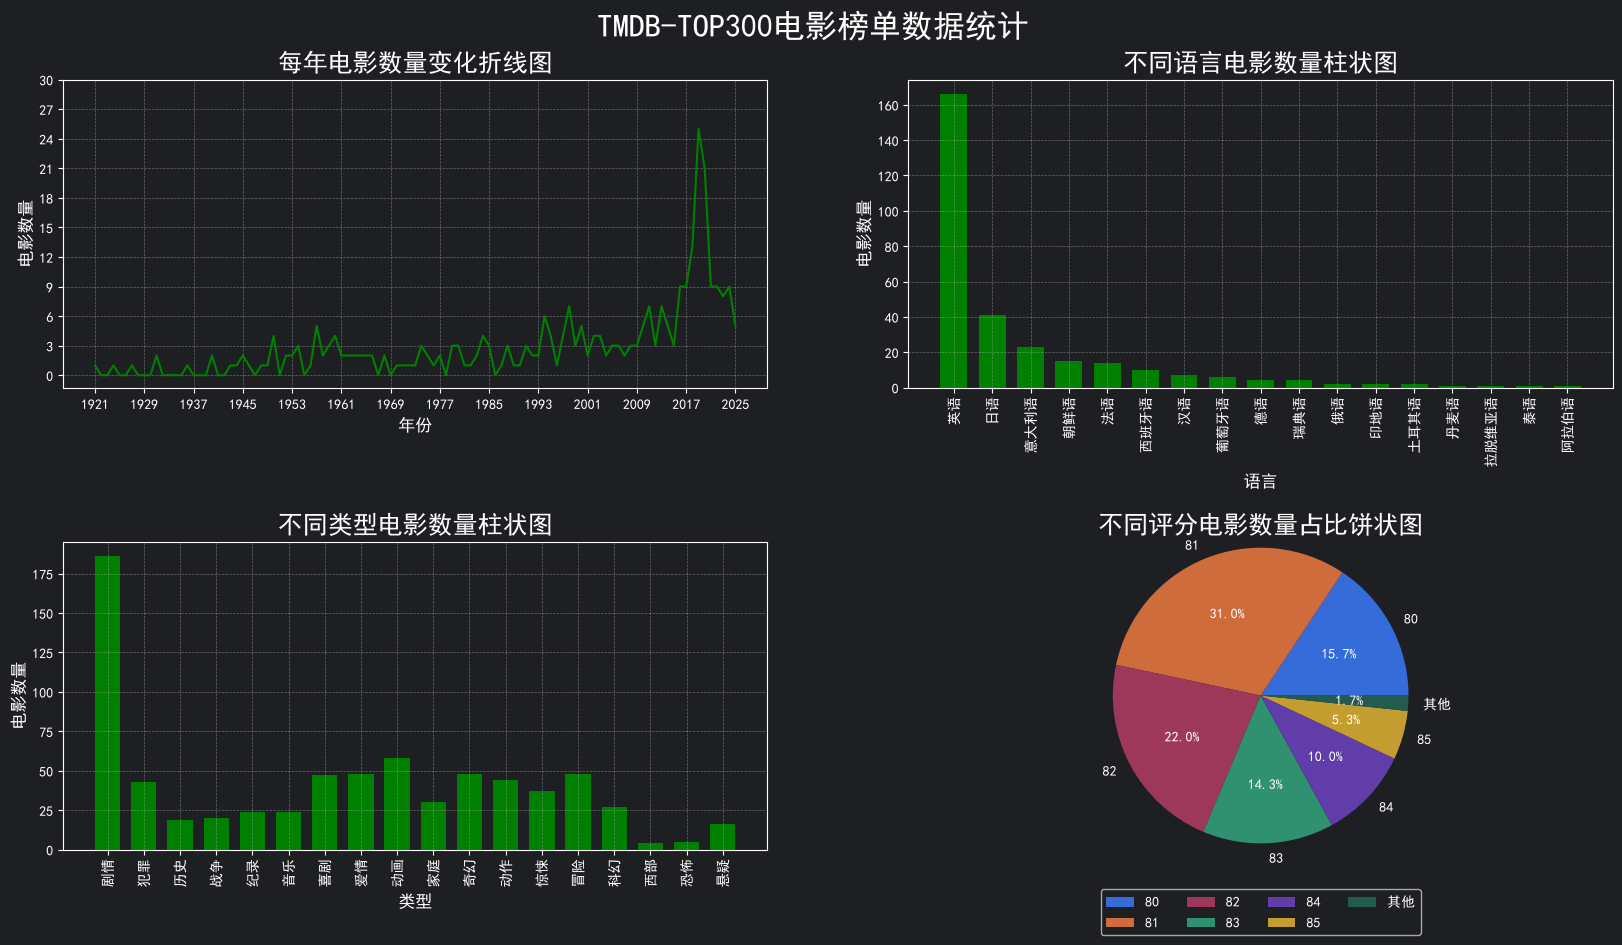

In [1]:
from pandas import Series
from matplotlib.axes import Axes
import pandas as pd
import matplotlib.pyplot as plt

#展示中文
plt.rcParams['font.sans-serif']=['SimHei']
#创建子图
fig,axes=plt.subplots(nrows=2,ncols=2,figsize=(20,10),dpi=100)
fig.suptitle('TMDB-TOP300电影榜单数据统计',fontsize=23,x=0.5,y=0.95) #添加画布标题 - x=0.5:x轴位置，y=0.95:y轴位置
fig.subplots_adjust(hspace=0.5,wspace=0.2) #调整子图间距:hspace=0.4:垂直间距，wspace=0.2:水平间距
#获取子图
axes1:Axes =axes[0][0]
axes2:Axes =axes[0][1]
axes3:Axes =axes[1,0]
axes4:Axes =axes[1,1]
#加载数据
#int64 :整型数字(不支持空值);
#Int64 :整型数字(支持空值);
#float64 :浮点型数字(支持空值);
data=pd.read_csv('movies.csv',usecols=['电影名','年份','上映时间','类型','时长','评分','语言'],dtype={'年份':'Int64'})

#1.需求一：统计每一年上映的电影数量的变化（折线图）
#1.1 缺失值、异常值处理
# data.isnull().sum()
data['年份']=data['年份'].fillna(data['上映时间'].str[:4].astype('Int64'))
#1.2 分组统计
year_count=data.groupby('年份')['年份'].count()
#1.3 组装数据
#x轴数据
min_year=year_count.index.min()
max_year=year_count.index.max()
x=[i for i in range(min_year,max_year+1)]
#y轴数据
y=[int(year_count.get(i,0)) for i in x]
#1.4 绘制折线图
axes1.plot(x,y,color='green')
axes1.set_title('每年电影数量变化折线图',fontsize=18)
axes1.set_xlabel('年份',fontsize=12) #x轴标签
axes1.set_ylabel('电影数量',fontsize=12) #y轴标签
axes1.set_xticks(x[::8]) #x轴刻度
y_ticks=[i for i in range(0,31,3)]
axes1.set_yticks(y_ticks) #y轴刻度
axes1.grid(linestyle='--',alpha=0.5) #网格线

#需求二：统计不同语言电影的数量（柱状图）
#2.1 获取不同语言对应的电影数量
language_count=data.groupby('语言')['语言'].count().sort_values(ascending=False)
x_language=language_count.index.tolist()
y_language_count=language_count.values.tolist()
#2.2 绘制柱状图
axes2.bar(x_language,y_language_count,color='green',width=0.7) #柱状图
axes2.set_title('不同语言电影数量柱状图',fontsize=18)
axes2.set_xlabel('语言',fontsize=12) #x轴标签
axes2.set_ylabel('电影数量',fontsize=12) #y轴标签
axes2.grid(linestyle='--',alpha=0.5) #网格线
axes2.tick_params(axis='x',rotation=90) #x轴标签旋转90度

#3.需求三:不同类型电影数量(柱状图)
#3.1 获取不同类型电影数量
type_count={} #{'类型':数量}
for types in data['类型'].str.split(','):#[剧情,犯罪]
    for type in types:
        if type in type_count:
            type_count[type]+=1
        else:
            type_count[type]=1
x_types=list(type_count.keys()) #类型列表
y_values=list(type_count.values()) #数量列表
#3.2 绘制柱状图
axes3.bar(x_types,y_values,color='green',width=0.7) #柱状图
axes3.set_title('不同类型电影数量柱状图',fontsize=18)
axes3.set_xlabel('类型',fontsize=12) #x轴标签
axes3.set_ylabel('电影数量',fontsize=12) #y轴标签
axes3.grid(linestyle='--',alpha=0.5) #网格线
axes3.tick_params(axis='x',rotation=90) #x轴标签旋转90度

#4.需求四：不同评分数量占比(饼状图)
#4.1 获取不同评分对应的电影数量
score_count=data.groupby('评分')['评分'].count()
#合并小数据(比例<2%)-->其他
total=score_count.sum()
large_scores:Series =score_count.loc[score_count/total>=0.02] #大数据，比例>=2%
small_scores:Series =score_count.loc[score_count/total<0.02] #小数据，比例<2%
if small_scores.shape[0]>0:
    large_scores['其他']=small_scores.sum()
scores=large_scores.index.tolist() #评分列表
scores_values=large_scores.values.tolist() #评分数量列表
#4.2 绘制饼状图
axes4.pie(scores_values,labels=scores,autopct='%1.1f%%',startangle=0,radius=1.2) #startangle:起始角度
axes4.set_title('不同评分电影数量占比饼状图',fontsize=18)
axes4.legend(loc='lower center',ncol=4,bbox_to_anchor=(0.5,-0.3))

#5.保存图片
plt.savefig('TMDB-TOP300.png')

plt.show() #显示画布